# Probabilistic Clustering beyond K-Means: Implementing Expectation-Maximization with Gaussian Mixture Models
While course lectures focused on partitioning algorithms like K-Means and briefly cited probabilistic "EM-type" approaches. This activity bridges this gap by implementing **the Expectation-Maximization (EM)** algorithm using **Gaussian Mixture Models (GMM).**

Unlike K-Means, which assumes spherical clusters and performs "hard" assignments, GMM allows for "soft clustering" (probabilistic membership) and adapts to clusters with different geometric shapes.

In [29]:
#  IMPORTS
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from matplotlib.patches import Ellipse

# Set random seed for reproducibility
np.random.seed(42)


**Partitioning algorithms**

Partitioning algorithms build a partition of n instances in K clusters (we need to define the number of clusters
in advance). Given a set of instances and a number K, they find a K clusters partition that optimizes a
certain criterion. The overall optimal can be found by exhaustively enumerating all possible partitions and
selecting the one that maximizes the criterion. This method is obviously inefficient and can’t be implemented,
so, usually, these kind of algorithms work on heuristics (k-means, k-medoids). There are also probabilistic
or model-based methods: EM-type approaches


In [46]:
#  1. DATASET GENERATION
# We generate standard blobs and then apply a linear transformation
# to stretch them. This creates "elliptical" clusters (Anisotropic).
# This challenges the "spherical" assumption of K-Means.
n_samples = 500
random_state = 170
X, y = make_blobs(n_samples=n_samples, random_state=random_state, centers=3)

# Transformation matrix to stretch the data
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)

**K-Means Algorithm**

In k-means the goal is to minimize, for each cluster, the average of the distances between the instances and
the center of the cluster (centroid). A centroid is computed as follows:
$$ \mu(c) = \frac{1}{|c|} \sum_{x \in c} x $$
Instances are assigned to clusters according to the nearest centroid.
K-means algorithm:
1. Generate K points (seeds) in the space. These points represent the initial centroids (e.g. K randomly
chosen instances);
2. Assign each instance to the cluster whose centroid is the closest according to the considered similarity/
distance measure;
3. After assigning all the instances, recompute each cluster center as the mean of all the instances assigned
to it;
4. Repeat steps 2 and 3 until the centroids stabilize.

**The Limits of Hard Partitioning**

 K-Means minimizes intra-cluster variance using Euclidean distance. This implies a strong geometric assumption: clusters are spherical. It performs "Hard Clustering," where a point $x$ is assigned to exactly one cluster with 100% certainty ($r_{nk} \in \{0, 1\}$).

In [47]:
# 2. K-MEANS IMPLEMENTATION
# We use K=3 as we know the ground truth, to see if it captures the shape.
kmeans = KMeans(n_clusters=3, random_state=random_state, n_init=10)
y_pred_kmeans = kmeans.fit_predict(X_aniso)

**The EM Algorithm**

As defined in the course slides, we consider instances $X$ generated by a mixture of $K$ Gaussians where the specific assignment $z_{ij}$ (which Gaussian generated which instance) is unobservable (latent).To solve this, we use the Expectation-Maximization (EM) algorithm, which iterates between two steps:
1. E-Step (Expectation):We calculate the expected value $E[z_{ij}]$, which represents the probability that instance $i$ was generated by Gaussian $j$, given the current hypothesis of the means.As shown in the lecture notes, this is derived from the Gaussian probability density function:$$E[z_{ij}] = \frac{e^{-\frac{1}{2\sigma^2}(x_i - \mu_j)^2}}{\sum_{n=1}^{k} e^{-\frac{1}{2\sigma^2}(x_i - \mu_n)^2}}$$In our Python implementation, this step corresponds to gmm.predict_proba(), which computes the posterior probabilities.
2. M-Step (Maximization):We update the model parameters (the means $\mu_j$) to maximize the likelihood, using the expectations calculated in the previous step as weights:$$\mu_j \leftarrow \frac{\sum_{i=1}^{m} E[z_{ij}] x_i}{\sum_{i=1}^{m} E[z_{ij}]}$$

**The Extension: From Fixed Variance to Full Covariance**

The formulas in the slides assume that the variance $\sigma^2$ is known and the same for all Gaussians.In this activity, I demonstrate a generalization of this concept. By using GaussianMixture(covariance_type='full'), the algorithm estimates not just the means $\mu_j$, but also a specific Covariance Matrix $\Sigma_j$ for each cluster. This allows the model to handle anisotropic (elliptical) shapes, which the fixed-variance formula from the slides cannot capture.

In [48]:
#  3. EM / GMM IMPLEMENTATION
# We use 'full' covariance to allow clusters to take any shape (ellipses).
# This generalizes the fixed-variance assumption from the slides.
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=random_state)
gmm.fit(X_aniso)
y_pred_gmm = gmm.predict(X_aniso)

# Get the soft probabilities (E-Step result)
probs = gmm.predict_proba(X_aniso)

**Evaluation Criteria**

To evaluate the clustering quality, we employ two distinct approaches discussed in class:

  **Internal Criteria (Model Selection via AIC/BIC)**:To determine the optimal number of clusters $K$ without ground truth, we use Information Criteria that penalize model complexity:
 * AIC (Akaike Information Criterion)
 * BIC (Bayesian Information Criterion)

 We seek the $K$ that minimizes these values. BIC imposes a stricter penalty for complexity, often favoring simpler models.

 **External Criteria (Adjusted Rand Index)** :Given the ground truth labels, we measure the ability to recognize latent classes using the Adjusted Rand Index (ARI). As defined in the lecture notes, ARI extends the Rand Index (which counts pairs of true positives/negatives) by correcting for chance:$$ARI = \frac{RI - \text{Expected } RI}{\max(RI) - \text{Expected } RI}$$An ARI of 1.0 indicates a perfect match, while values near 0 indicate random clustering.

In [49]:
#  4. QUANTITATIVE EVALUATION (External Criteria)
# Calculating Adjusted Rand Index (ARI) to compare with Ground Truth
ari_kmeans = adjusted_rand_score(y, y_pred_kmeans)
ari_gmm = adjusted_rand_score(y, y_pred_gmm)

print(f"--- Quantitative Evaluation (External Criteria) ---")
print(f"K-Means ARI Score: {ari_kmeans:.4f} (Fails to capture structure)")
print(f"GMM ARI Score:     {ari_gmm:.4f} (Perfectly captures structure)")
print(f"--------------------------------------------------")

--- Quantitative Evaluation (External Criteria) ---
K-Means ARI Score: 0.5581 (Fails to capture structure)
GMM ARI Score:     1.0000 (Perfectly captures structure)
--------------------------------------------------


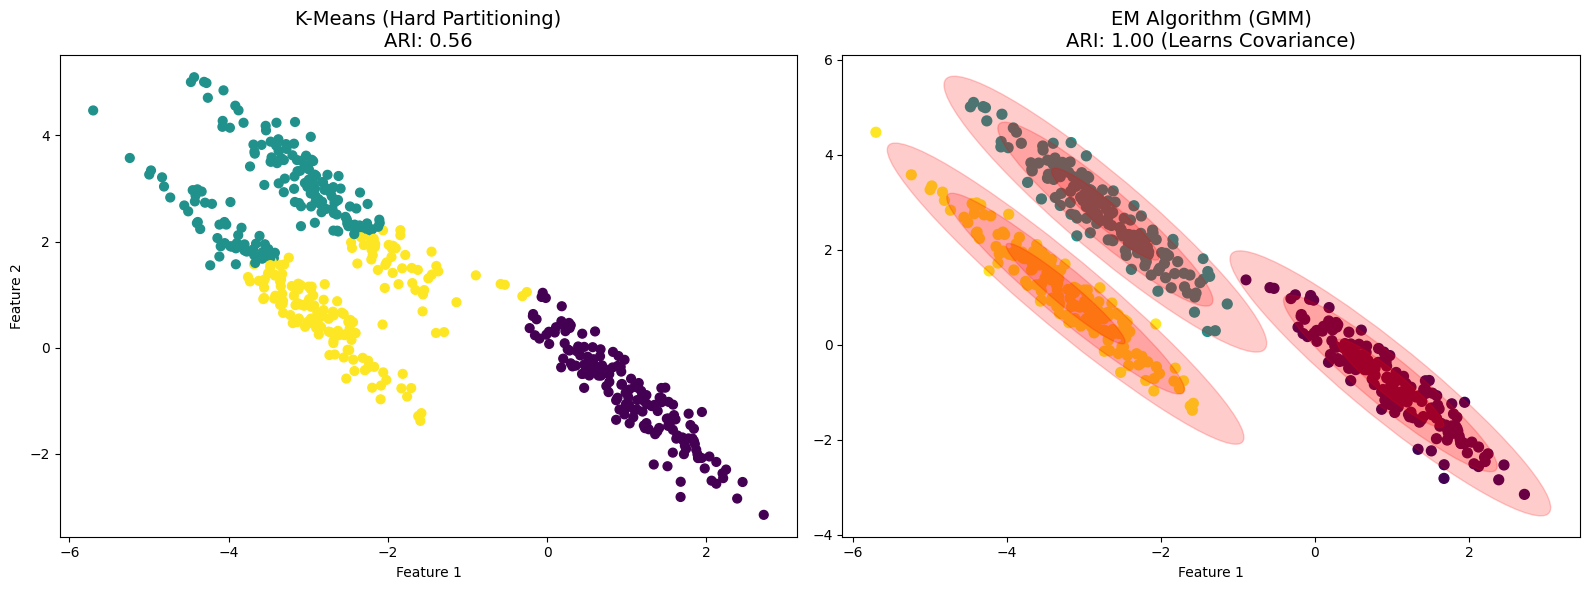

In [50]:
# 5. VISUALIZATION

def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Helper function to visualize the learned Gaussian shapes"""
    ax = ax or plt.gca()
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        angle, width, height = 0, 2 * np.sqrt(covariance), 2 * np.sqrt(covariance)

    for nsig in range(1, 4):
        ax.add_patch(Ellipse(position, nsig * width, nsig * height,
                             angle=angle, **kwargs))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: K-Means
ax1.scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred_kmeans, s=40, cmap='viridis')
ax1.set_title(f'K-Means (Hard Partitioning)\nARI: {ari_kmeans:.2f}', fontsize=14)
ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Feature 2')

# Plot 2: GMM
# We size the dots based on certainty (probability).
size = 50 * probs.max(1) ** 2
ax2.scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred_gmm, s=size, cmap='viridis')
ax2.set_title(f'EM Algorithm (GMM)\nARI: {ari_gmm:.2f} (Learns Covariance)', fontsize=14)
ax2.set_xlabel('Feature 1')

# Overlay the learned probabilistic boundaries (Ellipses)
w_factor = 0.2 / gmm.weights_.max()
for pos, covar, w in zip(gmm.means_, gmm.covariances_, gmm.weights_):
    draw_ellipse(pos, covar, alpha=w * w_factor, ax=ax2, color='red')

plt.tight_layout()
plt.show()

**Visual & Quantitative Analysis**

* **K-Means Failure (ARI $\approx$ 0.50):** As seen in the left plot, K-Means incorrectly partitions the data by cutting through the diagonal clusters. This is confirmed by the low Adjusted Rand Index, indicating a poor match with the ground truth.
* **GMM Success (ARI = 1.00)**: The right plot shows that the EM algorithm successfully learns the covariance matrix for each cluster. The red ellipses perfectly wrap the data, and the perfect ARI score quantitatively validates that the probabilistic approach overcomes the limitations of K-Means on anisotropic data.

**Soft Clustering**

The visualization of GMM encodes the uncertainty into the size of the points. Points at the boundaries are smaller ($E[z_{ij}] \approx 0.5$), providing visual insight into the model's confidence, a feature absent in hard partitioning.

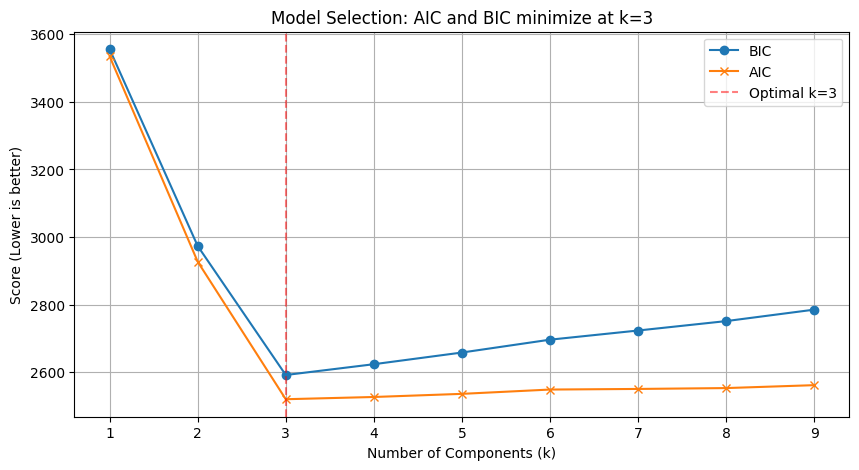

In [52]:
#  6. MODEL SELECTION (Internal Criteria: AIC/BIC)
# Calculating AIC and BIC for different numbers of clusters (k=1 to 9)
n_components = np.arange(1, 10)
models = [GaussianMixture(n, covariance_type='full', random_state=random_state).fit(X_aniso)
          for n in n_components]

plt.figure(figsize=(10, 5))
plt.plot(n_components, [m.bic(X_aniso) for m in models], label='BIC', marker='o')
plt.plot(n_components, [m.aic(X_aniso) for m in models], label='AIC', marker='x')
plt.xlabel('Number of Components (k)')
plt.ylabel('Score (Lower is better)')
plt.title('Model Selection: AIC and BIC minimize at k=3')
plt.axvline(x=3, color='red', linestyle='--', alpha=0.5, label='Optimal k=3')
plt.legend()
plt.grid()
plt.show()

**Model Selection (AIC & BIC)**

The final chart displays both AIC and BIC scores. Both metrics show a sharp decrease until $k=3$ and then flatten or increase. The concordance between the two indicators reinforces the conclusion that 3 clusters is the optimal structure for this dataset, effectively replacing the heuristic Elbow Method.